# Qiskit-Metal-to-Litho 12-qubit flux-tunable Xmon processor: a Quantcore-PDK rebuild, step by step

**Source:** Onri Jay Benally (OJB-Quantum), **Qiskit-Metal-to-Litho**, `12_Qubit_Flux_Tunable_Processor_in_Colab.ipynb`,
<https://github.com/OJB-Quantum/Qiskit-Metal-to-Litho>, licence **CC BY 4.0** (`LICENSE`; the notebook says "Open
Access (CC-BY-4.0)"; attribution: © Onri Jay Benally 2026, adapted). The notebook's design constants were read on
2026-11-03 (never executed); the repository now keeps it as `Python Code_Qiskit Metal_Designs/12_Flux_Tunable_Xmons_Colab.ipynb`,
whose GDS export cell was read on 2026-11-18 (the cheese row below). Spec: `docs/designs/community/qm2litho_12q_flux_processor.md`.

**What the chip is:** twelve flux-tunable Metal `TransmonCrossFL` Xmons in two columns of six (rows 1260 µm apart),
one column on each side of a straight vertical feedline (11.7/5.1 µm) between two launch pads. Each qubit has a claw
toward the line, a λ/4 meander readout multiplexed 6.05–6.82 GHz (70 MHz steps, L = v/(4f), v = 1.2 × 10⁸ m/s) and a
flux line fanned out to its own side pad. There are no qubit–qubit couplers: it is a readout and flux test processor.

**This notebook rebuilds the chip in the Quantcore PDK; it is not a replica.** What the rebuild keeps and what the PDK
changes:

| topic | source (Qiskit-Metal-to-Litho) | this rebuild |
|---|---|---|
| die and frame | Metal's 11 × 11 mm chip centred on (0, 0), no frame | PDK frame on the same 11 × 11 mm die (Designer = source + (5500, 5500) µm), device ID `QM2L-12Q` |
| stack | silicon (Metal default) | PDK sapphire 650 µm, εr 10.25 |
| qubits | Metal `TransmonCrossFL` (cross 260/35/20 µm, flux T-line, claw 190 × 10 µm) | the same cell and options through the `metal:` wrapper |
| junction | lumped L_J 15.904 nH, a flux-tunable SQUID in the circuit | a **Quantcore trilayer SQUID** drawn for L_J = 15.904 nH (`trilayer_junction(..., squid=True)`); R_n is flagged, not retuned |
| readout coupler | 3-tooth, 260 µm interdigital fingers 18 µm from the feedline | a qcc λ/4 hanger: 260 µm coupled section, 7 µm ground strip (the spec's reading of the 18 µm gap), shorted |
| launch and flux pads | `BondPad`-like pads 590–660 µm inside the chip edge | **PDK pad rule**: outer etch `frame.pad_edge` = 100 µm from the die edge (north/south launch pads, west/east flux pads) |
| cheese | **yes**: the notebook exports its GDS with Metal's `QGDSRenderer`, native cheesing on (25 µm squares every 100 µm, 25 µm buffer, 200 µm chip-edge margin) | **the original's**: Metal's rule drawn by the build (`cheese` = `metal_cheese_rule()`), no PDK band |
| netlist, LOM, FEM jobs | none | our netlist, LOM, and Q3D / eigenmode job exports per qubit |

**Simplified:** the meander is KQC's (5 turns, ≈ ±300 µm, the source's amplitude); PHIDL's Euler-smoothed centrelines
are not reproduced. The flux lines run at 6/8 µm all the way (no 95 µm taper to 5/3 µm at the qubit; the Metal flux
pin itself is 5/3 µm).

## 1 · Setup and the PDK

The notebook runs from the repository root. `_common` holds the table, snapshot and PDK helpers shared by the design
notebooks. `LIVE` follows `QCC_LIVE`: with KLayout open, every change below shows up live; with `QCC_LIVE=0` (tests,
batch runs) the snapshots are rendered headless.

In [1]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/community")
OUT.mkdir(parents=True, exist_ok=True)

The PDK facts this chip relies on. Every rule is applied by the library, not by this notebook: the frame and the
cheese by the chip build, the pad rule by `edge=`, the junction by `trilayer_junction`, the design warnings by the DRC.

In [2]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 2 · The die and the frame

`Designer(name, box=...)` opens an empty chip. The source's 11 × 11 mm chip is kept (the PDK frame fits any die size),
so Designer = source + (5500, 5500) µm. The PDK draws the frame round it: L dicing markers (1000/0), 3 × 3 alignment
grids (1001/0), the chip boundary (100/0) and the device ID (`name_chip`) on a free edge. 
**Cheese: the original's.** The source exports its GDS with Metal's `QGDSRenderer` and its native cheesing on
("Native Cheesing and GDS Export": `cheese.view_in_file` on for the metal layer, the renderer's default hole
size, pitch, buffer and edge margin), so the original has cheese and it wins over the PDK band:
`chip={"cheese": metal_cheese_rule()}` hands the build Metal's rule (25 µm squares every 100 µm, 25 µm clear of the
3/0 keep-outs, none within 200 µm of the die edge), and the build draws it instead of the band.

chip cheese rule: {'size': 25.0, 'gap': 75.0, 'rows': 1000, 'clearance': 25.0, 'edge': 200.0}


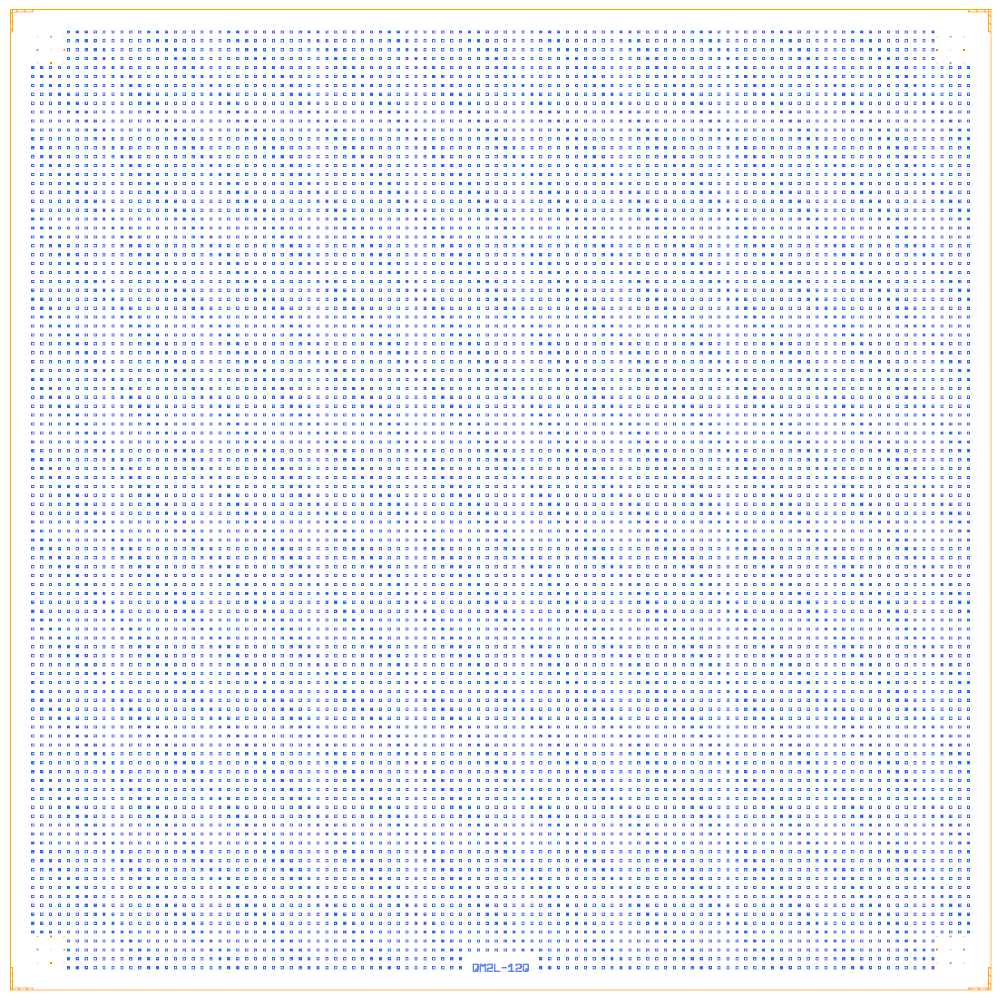

In [3]:
X0, Y0 = 5500, 5500                              # Metal's 11 × 11 mm chip is centred on (0, 0)
d = Designer("qm2litho_12q_flux_processor", box=(0, 0, 11000, 11000), chip={"name_chip": "QM2L-12Q", "cheese": metal_cheese_rule()},
             live=LIVE)
print("chip cheese rule:", d.design.chip.params["cheese"])
snap(d, OUT / "qm2litho_12q_flux_processor_die.png", size=(1000, 1000), width=360);

## 3 · Pads: launch pads, flux pads and the PDK pad rule

The source's launch pads (260 × 320 µm, 260 µm taper, 60 µm clearance, for the 11.7/5.1 µm feedline) sit at y = ±4200 µm
and its twelve flux pads (150 × 260 µm, 220 µm taper, 42 µm clearance, 6/8 µm lead) have their outer edge at
x = ±4850 µm: 590–660 µm inside the chip edge. The PDK puts every bond pad with the outer edge of its etch **`frame.pad_edge` =
100 µm from the die edge**, whatever the source did. `edge="n"` / `"s"` / `"w"` / `"e"` slides a pad perpendicular to that edge
until it holds and keeps its position along the edge, so every flux pad stays at its qubit's row.

In [4]:
LAUNCH = dict(pad_width=260, pad_height=320, taper_length=260, pad_gap=60, a=11.7, b=5.1)
FLUXPAD = dict(pad_width=150, pad_height=260, taper_length=220, pad_gap=42, a=6, b=8)
ROWS = (3150, 1890, 630, -630, -1890, -3150)     # source qubit rows (µm)
SITES = [(f"Q{row:02d}_{side}", x, y) for row, y in enumerate(ROWS, start=1) for side, x in (("L", -2350), ("R", 2350))]
with d.batch():
    top = d.add("P_TOP", "BondPad", at=(X0, Y0 + 4200), rot=180, edge="n", **LAUNCH)
    bot = d.add("P_BOT", "BondPad", at=(X0, Y0 - 4200), rot=0, edge="s", **LAUNCH)
    for name, x, y in SITES:
        left = x < 0
        d.add(f"F_{name}", "BondPad", at=(X0 + (-1 if left else 1) * (4850 - 260 - 220), Y0 + y),
              rot=270 if left else 90, edge="w" if left else "e", **FLUXPAD)
rebuild(d)
display(Markdown(pads_md(d)))

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P_TOP | `BondPad` | n | 100.0 | ✓ |
| P_BOT | `BondPad` | s | 100.0 | ✓ |
| F_Q01_L | `BondPad` | w | 100.0 | ✓ |
| F_Q01_R | `BondPad` | e | 100.0 | ✓ |
| F_Q02_L | `BondPad` | w | 100.0 | ✓ |
| F_Q02_R | `BondPad` | e | 100.0 | ✓ |
| F_Q03_L | `BondPad` | w | 100.0 | ✓ |
| F_Q03_R | `BondPad` | e | 100.0 | ✓ |
| F_Q04_L | `BondPad` | w | 100.0 | ✓ |
| F_Q04_R | `BondPad` | e | 100.0 | ✓ |
| F_Q05_L | `BondPad` | w | 100.0 | ✓ |
| F_Q05_R | `BondPad` | e | 100.0 | ✓ |
| F_Q06_L | `BondPad` | w | 100.0 | ✓ |
| F_Q06_R | `BondPad` | e | 100.0 | ✓ |

**The feedline** is a straight 11.7/5.1 µm CPW from the top launch pad's port `a` to the bottom one's, with 70 µm bends.
It travels −y, so its "right" side is the west column and its "left" side the east column.

In [5]:
fl = d.route("FL", top.a, bot.a, a=11.7, b=5.1, r=70)
rebuild(d)
print(f"FL: {fl.length:.1f} µm")

FL: 9520.0 µm


## 4 · Components: twelve flux-tunable Xmons with trilayer SQUIDs

**The junction.** The source gives L_J = 15.904 nH for every qubit; its qubits are flux-tunable, so the junction is a
SQUID (the LOM model of `TransmonCrossFL` treats it as one, with the flux line as a flux-bias control).
`trilayer_junction(cell, lj_nH=15.904, squid=True)` draws a Quantcore trilayer SQUID (two junctions in a loop, fingers
on 2/0 and 4/0, spacer 50/0 with the 51–53/0 gradient) whose total L_J at zero flux is 15.9 nH, and returns the values
the LOM uses. The PDK window judges the device, the SQUID's two junctions in parallel: drawn on the PDK finger grid the 15.9 nH comes
out as 15.31 nH, so its R_n is 102 kΩ (each junction 205 kΩ), **outside the PDK window of 40–50 kΩ**. Following the project rule (values are flagged, never
retuned), the source's L_J stays and the DRC reports the design warning `pdk_rn`.

In [6]:
LJ_NH = 15.903982                                # the source's Lj (zero-flux SQUID inductance)
JJP, JJ = trilayer_junction("metal:TransmonCrossFL", lj_nH=LJ_NH, squid=True)
print("cell parameters:", JJP)
print("LOM SQUID:      ", JJ, f"→ device R_n {rn_from_lj(JJ['Lj_nH']) / 1e3:.1f} kΩ (each junction "
      f"{rn_from_lj(2 * JJ['Lj_nH']) / 1e3:.0f} kΩ; PDK window 40–50 kΩ)")

cell parameters: {'junction_type': 'Quantcore Squid', 'junction_params': {'lj_nH': 15.903982}}
LOM SQUID:       {'Lj_nH': 15.3055, 'Cj_fF': 6.6} → device R_n 102.3 kΩ (each junction 205 kΩ; PDK window 40–50 kΩ)


**The qubits.** Metal `TransmonCrossFL`: cross 260 µm arms, 35 µm wide, 20 µm gap; a flux T-line at the bottom arm
(`t_top` 24 µm, 4 µm inductive gap, 5/3 µm); one claw (190 × 10 µm, 6 µm gap, 5 µm ground spacing, no claw CPW) on the
arm facing the line. The west column is rotated −90° and the east column +90°, so every claw faces the feedline and
every flux line faces its side pad. `q.c` is the claw pin, `q.flux_line` the flux pin.

<metal:TransmonCrossFL Q01_L ports=['c', 'flux_line', 'squid_a', 'squid_b']>


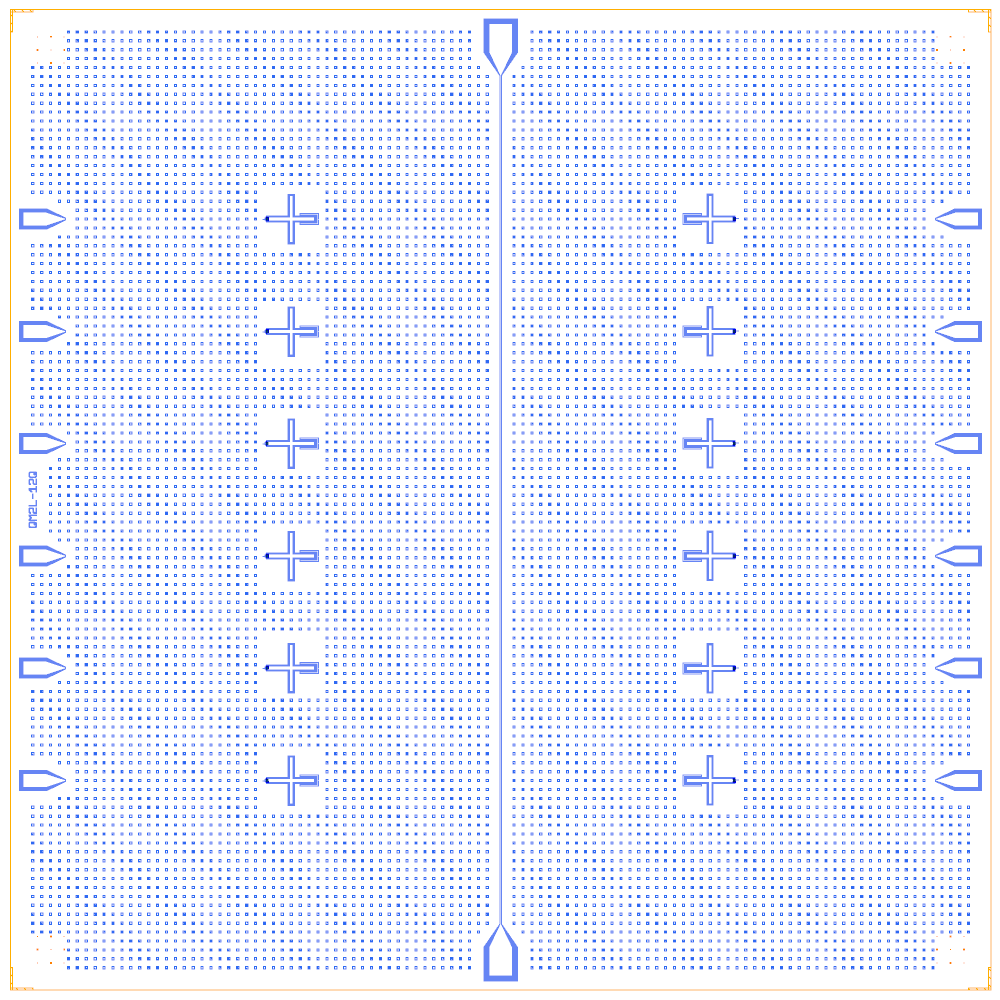

In [7]:
CLAW = dict(connector_location="90", connector_type="0", claw_length=190, claw_gap=6, claw_width=10,
            claw_cpw_length=0, claw_cpw_width=10, ground_spacing=5)
XMON_FL = dict(cross_length=260, cross_width=35, cross_gap=20, make_fl=True,
               fl_options={"t_top": 24, "t_offset": 0, "t_inductive_gap": 4, "t_width": 5, "t_gap": 3},
               connection_pads={"c": CLAW})
qubits = {}
with d.batch():
    for name, x, y in SITES:
        qubits[name] = d.add(name, "metal:TransmonCrossFL", at=(X0 + x, Y0 + y), rot=-90 if x < 0 else 90,
                             junction=JJ, **XMON_FL, **JJP)
print(qubits["Q01_L"])
snap(d, OUT / "qm2litho_12q_flux_processor_components.png", size=(1000, 1000), width=360);

## 5 · Routes: λ/4 hanger readouts and flux lines

**Readouts.** Each readout is one qcc route: claw → meander → a 260 µm section along the feedline with a 7 µm ground
strip → short to ground.
- `fl.hanger(near=(x, y), length=260, side=..., ground_gap=7, end="short")` centres the coupled section at the
  feedline point nearest (x, y), here 130 µm below the qubit's row. Placing it by position, not by arclength from the
  launch pad, keeps it at its qubit when the pad moves.
- `meander=L_k` is the source's L_k = v / (4 f_k) (the coupled section included), 5 meanders, 85 µm bends.
- The frequency plan runs in site order: Q01_L 6.05, Q01_R 6.12, Q02_L 6.19 GHz, … Q06_R 6.82 GHz.

**Flux lines.** `FLX_<q>` runs from the qubit's flux pin to its side pad at 6/8 µm with 55 µm bends. The LOM reads a
line that ends on a flux pin as a flux-bias control, not as a resonator.

{'FL': 9520.0, 'R_Q01_L': 4958.7, 'FLX_Q01_L': 2208.5, 'R_Q01_R': 4902.0, 'FLX_Q01_R': 2208.5, 'FLX_Q02_L': 2208.5, 'FLX_Q02_R': 2208.5, 'FLX_Q03_L': 2208.5, 'FLX_Q03_R': 2208.5, 'FLX_Q04_L': 2208.5, 'FLX_Q04_R': 2208.5, 'FLX_Q05_L': 2208.5, 'FLX_Q05_R': 2208.5, 'FLX_Q06_L': 2208.5, 'FLX_Q06_R': 2208.5}


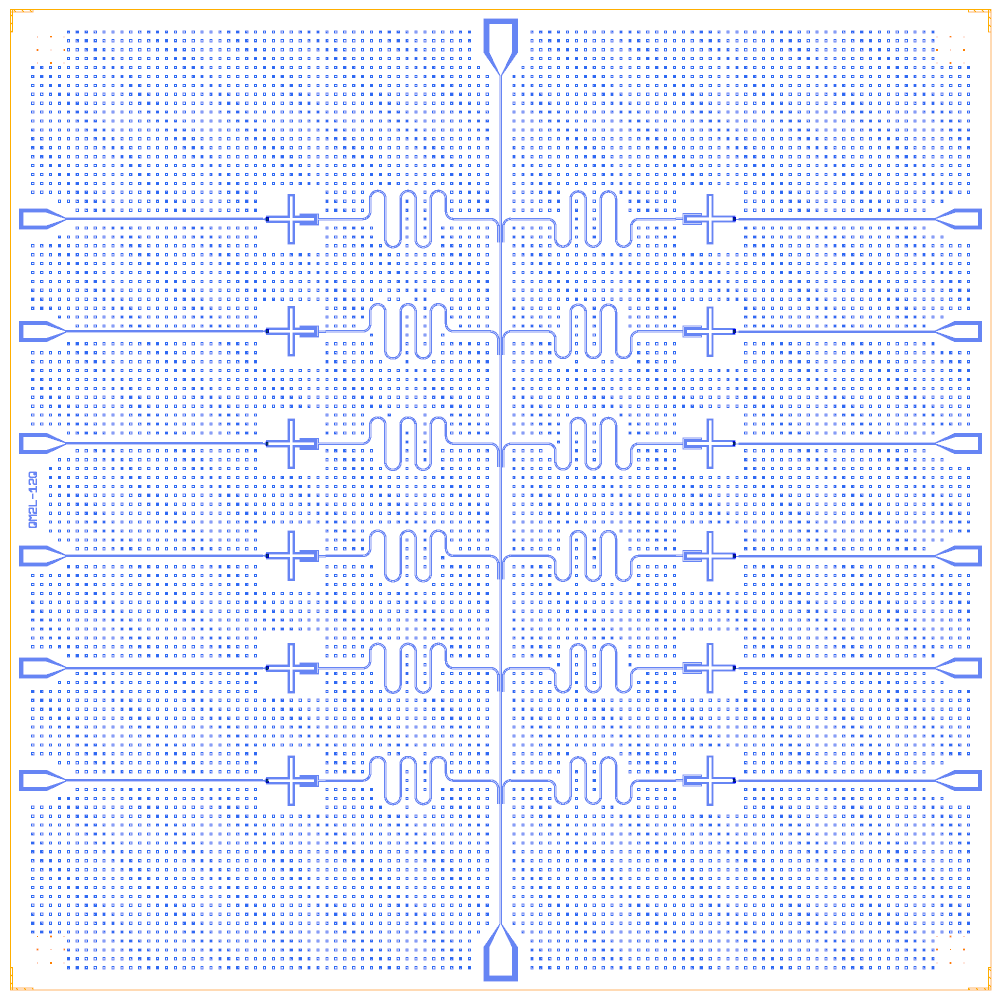

In [8]:
F_GHZ = [6.05 + 0.07 * k for k in range(12)]     # site order Q01_L, Q01_R, Q02_L, ...
with d.batch():
    for (name, x, y), f in zip(SITES, F_GHZ):
        left = x < 0
        L = 1.20e8 / (4 * f * 1e9) * 1e6         # source L_k = v / (4 f_k), µm
        hg = fl.hanger(near=(X0, Y0 + y - 130), length=260, side="right" if left else "left", ground_gap=7,
                       direction="forward", end="short")
        d.route(f"R_{name}", qubits[name].c, hg, meander=round(L, 1), r=85).set(meanders=5)
        d.route(f"FLX_{name}", qubits[name].flux_line, d[f"F_{name}"].a, a=6, b=8, r=55)
        d.targets(**{f"R_{name}": {"f_GHz": round(f, 3)}})
        d.sim_group(name, [name, f"R_{name}", "FL", f"FLX_{name}"])
rebuild(d)
lengths = d.result.route_lengths()
print({k: round(v, 1) for k, v in lengths.items() if k.startswith(("FL", "R_Q01", "FLX_Q01"))})
snap(d, OUT / "qm2litho_12q_flux_processor_routes.png", size=(1000, 1000), width=360);

## 6 · PDK placement: centring

The source chip is symmetric about its centre and the rebuild keeps the source coordinates, so the content is already
centred: `center_in_die(d)` measures the bounding box of every instance and route and returns (0, 0) when it is
within 50 µm of the die centre (it would shift everything otherwise).

In [9]:
print("shift applied (µm):", center_in_die(d))

shift applied (µm): (0.0, 0.0)


## 7 · DRC

`d.drc()` checks connectivity (dangling ports, overlaps, route crossings, netlist opens and shorts) and the PDK margins:
- **errors** would make the chip wrong; there must be none;
- **warnings** are worth a look but can be intended: here the SQUID attachment points (`squid_a` / `squid_b`; the
  cell draws its own junction), not route ends;
- **PDK design warnings** flag values outside the PDK margins (`pdk_rn`, `pdk_fq`, `pad_edge`, `pdk_claw`); they are
  reported, never enforced. Here: `pdk_rn` on all twelve SQUIDs (device R_n 102.3 kΩ at the source's
  15.9 nH).

Expected (this run): **no errors**; 24 `dangling_port` warnings, the twelve SQUIDs' `squid_a` / `squid_b`; 12 `pdk_rn`.
No `pad_edge`: the 14 pads sit at 100 µm.

`pdk_report(d)` sums up the PDK checks.

In [10]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 24 warnings · 12 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 24 | Q01_L.squid_a is not connected (no route or snap) |
| PDK design warning | `pdk_rn` | 12 | Q01_L: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |

| check | value |
|---|---|
| cheese | the original design's rule (drawn in the build): size 25, gap 75, rows 1000, clearance 25, edge 200 |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Squid × 12 |
| PDK design warnings | 12 (pdk_rn × 12) |
| pdk_rn | Q01_L: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |
| pdk_rn | Q01_R: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |
| pdk_rn | Q02_L: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |
| pdk_rn | Q02_R: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |
| pdk_rn | Q03_L: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |
| pdk_rn | Q03_R: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |
| pdk_rn | Q04_L: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |
| pdk_rn | Q04_R: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |
| pdk_rn | Q05_L: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |
| pdk_rn | Q05_R: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |
| pdk_rn | Q06_L: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |
| pdk_rn | Q06_R: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit. Each `TransmonCrossFL` is a grounded island with its SQUID to ground,
a claw node and a flux-bias control (`FLX_<q>`). Each readout is a λ/4 `TLres` from the claw node with a `HANGER` (κ)
to the feedline node `FL`, which carries the two 50 Ω launch-pad ports. The flux pads are not circuit nodes: the flux
lines are controls.

In [11]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

**26 nodes · 74 branches · 12 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL` | `FL`, `P_TOP.pad`, `P_BOT.pad` |
| `Q01_L` | `Q01_L.island` |
| `Q01_L.c` | `Q01_L.c` |
| `Q01_R` | `Q01_R.island` |
| `Q01_R.c` | `Q01_R.c` |
| `Q02_L` | `Q02_L.island` |
| `Q02_L.c` | `Q02_L.c` |
| `Q02_R` | `Q02_R.island` |
| `Q02_R.c` | `Q02_R.c` |
| `Q03_L` | `Q03_L.island` |
| `Q03_L.c` | `Q03_L.c` |
| `Q03_R` | `Q03_R.island` |
| `Q03_R.c` | `Q03_R.c` |
| `Q04_L` | `Q04_L.island` |
| `Q04_L.c` | `Q04_L.c` |
| `Q04_R` | `Q04_R.island` |
| `Q04_R.c` | `Q04_R.c` |
| `Q05_L` | `Q05_L.island` |
| `Q05_L.c` | `Q05_L.c` |
| `Q05_R` | `Q05_R.island` |
| `Q05_R.c` | `Q05_R.c` |
| `Q06_L` | `Q06_L.island` |
| `Q06_L.c` | `Q06_L.c` |
| `Q06_R` | `Q06_R.island` |
| `Q06_R.c` | `Q06_R.c` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_P_TOP` | R | `FL` – `gnd` | 50 Ω |
| `Port_P_BOT` | R | `FL` – `gnd` | 50 Ω |
| `C_Q01_L` | C | `Q01_L` – `gnd` | 132 fF |
| `J_Q01_L` | SQUID | `Q01_L` – `gnd` | Lj 15.3 nH, Cj 6.6 fF |
| `Cg_Q01_L_c` | C | `Q01_L` – `Q01_L.c` | 4.6 fF |
| `Cc_Q01_L_c` | C | `Q01_L.c` – `gnd` | 73.4 fF |
| `C_Q01_R` | C | `Q01_R` – `gnd` | 132 fF |
| `J_Q01_R` | SQUID | `Q01_R` – `gnd` | Lj 15.3 nH, Cj 6.6 fF |
| `Cg_Q01_R_c` | C | `Q01_R` – `Q01_R.c` | 4.6 fF |
| `Cc_Q01_R_c` | C | `Q01_R.c` – `gnd` | 73.4 fF |
| `C_Q02_L` | C | `Q02_L` – `gnd` | 132 fF |
| `J_Q02_L` | SQUID | `Q02_L` – `gnd` | Lj 15.3 nH, Cj 6.6 fF |
| `Cg_Q02_L_c` | C | `Q02_L` – `Q02_L.c` | 4.6 fF |
| `Cc_Q02_L_c` | C | `Q02_L.c` – `gnd` | 73.4 fF |
| `C_Q02_R` | C | `Q02_R` – `gnd` | 132 fF |
| `J_Q02_R` | SQUID | `Q02_R` – `gnd` | Lj 15.3 nH, Cj 6.6 fF |
| `Cg_Q02_R_c` | C | `Q02_R` – `Q02_R.c` | 4.6 fF |
| `Cc_Q02_R_c` | C | `Q02_R.c` – `gnd` | 73.4 fF |
| `C_Q03_L` | C | `Q03_L` – `gnd` | 132 fF |
| `J_Q03_L` | SQUID | `Q03_L` – `gnd` | Lj 15.3 nH, Cj 6.6 fF |
| `Cg_Q03_L_c` | C | `Q03_L` – `Q03_L.c` | 4.6 fF |
| `Cc_Q03_L_c` | C | `Q03_L.c` – `gnd` | 73.4 fF |
| `C_Q03_R` | C | `Q03_R` – `gnd` | 132 fF |
| `J_Q03_R` | SQUID | `Q03_R` – `gnd` | Lj 15.3 nH, Cj 6.6 fF |
| `Cg_Q03_R_c` | C | `Q03_R` – `Q03_R.c` | 4.6 fF |
| `Cc_Q03_R_c` | C | `Q03_R.c` – `gnd` | 73.4 fF |
| `C_Q04_L` | C | `Q04_L` – `gnd` | 132 fF |
| `J_Q04_L` | SQUID | `Q04_L` – `gnd` | Lj 15.3 nH, Cj 6.6 fF |
| `Cg_Q04_L_c` | C | `Q04_L` – `Q04_L.c` | 4.6 fF |
| `Cc_Q04_L_c` | C | `Q04_L.c` – `gnd` | 73.4 fF |
| `C_Q04_R` | C | `Q04_R` – `gnd` | 132 fF |
| `J_Q04_R` | SQUID | `Q04_R` – `gnd` | Lj 15.3 nH, Cj 6.6 fF |
| `Cg_Q04_R_c` | C | `Q04_R` – `Q04_R.c` | 4.6 fF |
| `Cc_Q04_R_c` | C | `Q04_R.c` – `gnd` | 73.4 fF |
| `C_Q05_L` | C | `Q05_L` – `gnd` | 132 fF |
| `J_Q05_L` | SQUID | `Q05_L` – `gnd` | Lj 15.3 nH, Cj 6.6 fF |
| `Cg_Q05_L_c` | C | `Q05_L` – `Q05_L.c` | 4.6 fF |
| `Cc_Q05_L_c` | C | `Q05_L.c` – `gnd` | 73.4 fF |
| `C_Q05_R` | C | `Q05_R` – `gnd` | 132 fF |
| `J_Q05_R` | SQUID | `Q05_R` – `gnd` | Lj 15.3 nH, Cj 6.6 fF |
| `Cg_Q05_R_c` | C | `Q05_R` – `Q05_R.c` | 4.6 fF |
| `Cc_Q05_R_c` | C | `Q05_R.c` – `gnd` | 73.4 fF |
| `C_Q06_L` | C | `Q06_L` – `gnd` | 132 fF |
| `J_Q06_L` | SQUID | `Q06_L` – `gnd` | Lj 15.3 nH, Cj 6.6 fF |
| `Cg_Q06_L_c` | C | `Q06_L` – `Q06_L.c` | 4.6 fF |
| `Cc_Q06_L_c` | C | `Q06_L.c` – `gnd` | 73.4 fF |
| `C_Q06_R` | C | `Q06_R` – `gnd` | 132 fF |
| `J_Q06_R` | SQUID | `Q06_R` – `gnd` | Lj 15.3 nH, Cj 6.6 fF |
| `Cg_Q06_R_c` | C | `Q06_R` – `Q06_R.c` | 4.6 fF |
| `Cc_Q06_R_c` | C | `Q06_R.c` – `gnd` | 73.4 fF |
| `R_Q01_L` | TLres | `Q01_L.c` – `gnd` | lambda/4, 4959 µm, 6.354 GHz |
| `K_R_Q01_L` | HANGER | `Q01_L.c` – `FL` | κ 0.0985 MHz (L 260 µm) |
| `R_Q01_R` | TLres | `Q01_R.c` – `gnd` | lambda/4, 4902 µm, 6.428 GHz |
| `K_R_Q01_R` | HANGER | `Q01_R.c` – `FL` | κ 0.102 MHz (L 260 µm) |
| `R_Q02_L` | TLres | `Q02_L.c` – `gnd` | lambda/4, 4847 µm, 6.501 GHz |
| `K_R_Q02_L` | HANGER | `Q02_L.c` – `FL` | κ 0.106 MHz (L 260 µm) |
| `R_Q02_R` | TLres | `Q02_R.c` – `gnd` | lambda/4, 4792 µm, 6.575 GHz |
| `K_R_Q02_R` | HANGER | `Q02_R.c` – `FL` | κ 0.109 MHz (L 260 µm) |
| `R_Q03_L` | TLres | `Q03_L.c` – `gnd` | lambda/4, 4739 µm, 6.648 GHz |
| `K_R_Q03_L` | HANGER | `Q03_L.c` – `FL` | κ 0.113 MHz (L 260 µm) |
| `R_Q03_R` | TLres | `Q03_R.c` – `gnd` | lambda/4, 4688 µm, 6.722 GHz |
| `K_R_Q03_R` | HANGER | `Q03_R.c` – `FL` | κ 0.117 MHz (L 260 µm) |
| `R_Q04_L` | TLres | `Q04_L.c` – `gnd` | lambda/4, 4637 µm, 6.795 GHz |
| `K_R_Q04_L` | HANGER | `Q04_L.c` – `FL` | κ 0.12 MHz (L 260 µm) |
| `R_Q04_R` | TLres | `Q04_R.c` – `gnd` | lambda/4, 4587 µm, 6.869 GHz |
| `K_R_Q04_R` | HANGER | `Q04_R.c` – `FL` | κ 0.124 MHz (L 260 µm) |
| `R_Q05_L` | TLres | `Q05_L.c` – `gnd` | lambda/4, 4539 µm, 6.942 GHz |
| `K_R_Q05_L` | HANGER | `Q05_L.c` – `FL` | κ 0.128 MHz (L 260 µm) |
| `R_Q05_R` | TLres | `Q05_R.c` – `gnd` | lambda/4, 4491 µm, 7.016 GHz |
| `K_R_Q05_R` | HANGER | `Q05_R.c` – `FL` | κ 0.133 MHz (L 260 µm) |
| `R_Q06_L` | TLres | `Q06_L.c` – `gnd` | lambda/4, 4444 µm, 7.090 GHz |
| `K_R_Q06_L` | HANGER | `Q06_L.c` – `FL` | κ 0.137 MHz (L 260 µm) |
| `R_Q06_R` | TLres | `Q06_R.c` – `gnd` | lambda/4, 4399 µm, 7.163 GHz |
| `K_R_Q06_R` | HANGER | `Q06_R.c` – `FL` | κ 0.141 MHz (L 260 µm) |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `FLX_Q01_L` | flux_bias | `J_Q01_L` | `FLX_Q01_L` | 2208 |
| `FLX_Q01_R` | flux_bias | `J_Q01_R` | `FLX_Q01_R` | 2208 |
| `FLX_Q02_L` | flux_bias | `J_Q02_L` | `FLX_Q02_L` | 2208 |
| `FLX_Q02_R` | flux_bias | `J_Q02_R` | `FLX_Q02_R` | 2208 |
| `FLX_Q03_L` | flux_bias | `J_Q03_L` | `FLX_Q03_L` | 2208 |
| `FLX_Q03_R` | flux_bias | `J_Q03_R` | `FLX_Q03_R` | 2208 |
| `FLX_Q04_L` | flux_bias | `J_Q04_L` | `FLX_Q04_L` | 2208 |
| `FLX_Q04_R` | flux_bias | `J_Q04_R` | `FLX_Q04_R` | 2208 |
| `FLX_Q05_L` | flux_bias | `J_Q05_L` | `FLX_Q05_L` | 2208 |
| `FLX_Q05_R` | flux_bias | `J_Q05_R` | `FLX_Q05_R` | 2208 |
| `FLX_Q06_L` | flux_bias | `J_Q06_L` | `FLX_Q06_L` | 2208 |
| `FLX_Q06_R` | flux_bias | `J_Q06_R` | `FLX_Q06_R` | 2208 |

**Unconnected ports:** none

**Builder notes:**

- Port_F_Q01_L: both ends on gnd after merging conductors (dropped)
- Port_F_Q01_R: both ends on gnd after merging conductors (dropped)
- Port_F_Q02_L: both ends on gnd after merging conductors (dropped)
- Port_F_Q02_R: both ends on gnd after merging conductors (dropped)
- Port_F_Q03_L: both ends on gnd after merging conductors (dropped)
- Port_F_Q03_R: both ends on gnd after merging conductors (dropped)
- Port_F_Q04_L: both ends on gnd after merging conductors (dropped)
- Port_F_Q04_R: both ends on gnd after merging conductors (dropped)
- Port_F_Q05_L: both ends on gnd after merging conductors (dropped)
- Port_F_Q05_R: both ends on gnd after merging conductors (dropped)
- Port_F_Q06_L: both ends on gnd after merging conductors (dropped)
- Port_F_Q06_R: both ends on gnd after merging conductors (dropped)

{'nodes': 25, 'branches': 74, 'controls': 12, 'unconnected': 0}


## 9 · LOM simulation (per qubit / readout pair, with the feedline)

Each qubit is simulated with its readout and the feedline (QuCat normal modes, then the QuTiP dressed values), at zero
flux. Targets in brackets are the source's readout plan. The source states no qubit frequency.

What the table shows (this run):
- every qubit at **3.258 GHz** (α −150 MHz) with the drawn 15.31 nH SQUID: below the PDK band of 4–8 GHz (no qubit
  target is set, so the DRC has no `pdk_fq` warning to give);
- the readouts at **5.742 … 6.399 GHz** in 60 MHz steps, 5–6 % below the source's plan (6.05 … 6.82 GHz): the source's
  L = v/(4f) takes v = 1.2 × 10⁸ m/s, the PDK CPW on sapphire (with the Nb kinetic inductance) is slower and the claw
  loads the open end. Flagged, not retuned (the source's lengths are kept);
- κ 0.066–0.090 MHz through the 260 µm hangers; χ −0.10 … −0.12 MHz, small because the qubits sit 2.5–3.1 GHz below
  their readouts.

In [12]:
groups = {n: [n, f"R_{n}", "FL"] for n, _, _ in SITES}
res = simulate_groups(d, groups)
display(Markdown(groups_md(res, d.data["targets"])))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q01_L | Q01_L | 3.258 | -150.1 | R_Q01_L | 5.7421 (6.05) | 0.0657 | -0.12 |
| Q01_R | Q01_R | 3.258 | -150.1 | R_Q01_R | 5.8023 (6.12) | 0.0677 | -0.117 |
| Q02_L | Q02_L | 3.258 | -150.1 | R_Q02_L | 5.8626 (6.19) | 0.0698 | -0.115 |
| Q02_R | Q02_R | 3.258 | -150.1 | R_Q02_R | 5.9226 (6.26) | 0.0718 | -0.113 |
| Q03_L | Q03_L | 3.258 | -150.1 | R_Q03_L | 5.9825 (6.33) | 0.074 | -0.112 |
| Q03_R | Q03_R | 3.258 | -150.1 | R_Q03_R | 6.0423 (6.4) | 0.0761 | -0.11 |
| Q04_L | Q04_L | 3.258 | -150.1 | R_Q04_L | 6.1019 (6.47) | 0.0783 | -0.108 |
| Q04_R | Q04_R | 3.258 | -150.1 | R_Q04_R | 6.1614 (6.54) | 0.0805 | -0.107 |
| Q05_L | Q05_L | 3.258 | -150.1 | R_Q05_L | 6.2209 (6.61) | 0.0828 | -0.105 |
| Q05_R | Q05_R | 3.258 | -150.1 | R_Q05_R | 6.2803 (6.68) | 0.0851 | -0.104 |
| Q06_L | Q06_L | 3.258 | -150.1 | R_Q06_L | 6.3395 (6.75) | 0.0874 | -0.103 |
| Q06_R | Q06_R | 3.258 | -150.1 | R_Q06_R | 6.3986 (6.82) | 0.0898 | -0.101 |

## 10 · FEM: send the job

Every qubit's sim group (qubit, readout, feedline, flux line) is exported as a Q3D C-matrix job (capacitances by net
name) and an eigenmode/EPR job, in self-contained folders `build/jobs/<design>_<group>_<analysis>`. Exporting again
replaces a folder, results included. Simulation exports never carry cheese.

`RUN_FEM = False` only exports. With `RUN_FEM = True` and AEDT 2024 R1 (or newer) on this machine, `send_fem_jobs` solves
each job in a **new batch, non-graphical AEDT** (`solve_job`); an AEDT window you have open is never touched. Elsewhere:
`qcc hfss solve build/jobs/<job>`.

In [13]:
RUN_FEM = False                                  # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
DESIGN = d.save(OUT / "qm2litho_12q_flux_processor.json")
sites = [n for n, _, _ in SITES]
jobs = export_sims(DESIGN, sites, analysis="q3d_cmatrix")
jobs_eig = export_sims(DESIGN, sites, analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))
if RUN_FEM:
    send_fem_jobs(DESIGN, sites, analyses=["q3d_cmatrix", "eigenmode_epr"], run=True)

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q01_L | `build/jobs/qm2litho_12q_flux_processor_Q01_L_q3d_cmatrix` | 1 · junction · `Q01_L.junction`<br>2 · waveguide · `Q01_L.c`<br>3 · waveguide · `Q01_L.flux_line`<br>4 · lumped · `F_Q01_L.pad`<br>5 · lumped · `P_BOT.pad`<br>6 · lumped · `P_TOP.pad` | `Q01_L.island`, `Q01_L.c`, `P_BOT.pad` |
| Q01_R | `build/jobs/qm2litho_12q_flux_processor_Q01_R_q3d_cmatrix` | 1 · junction · `Q01_R.junction`<br>2 · waveguide · `Q01_R.c`<br>3 · waveguide · `Q01_R.flux_line`<br>4 · lumped · `F_Q01_R.pad`<br>5 · lumped · `P_BOT.pad`<br>6 · lumped · `P_TOP.pad` | `Q01_R.island`, `Q01_R.c`, `P_BOT.pad` |
| Q02_L | `build/jobs/qm2litho_12q_flux_processor_Q02_L_q3d_cmatrix` | 1 · junction · `Q02_L.junction`<br>2 · waveguide · `Q02_L.c`<br>3 · waveguide · `Q02_L.flux_line`<br>4 · lumped · `F_Q02_L.pad`<br>5 · lumped · `P_BOT.pad`<br>6 · lumped · `P_TOP.pad` | `Q02_L.island`, `Q02_L.c`, `P_BOT.pad` |
| Q02_R | `build/jobs/qm2litho_12q_flux_processor_Q02_R_q3d_cmatrix` | 1 · junction · `Q02_R.junction`<br>2 · waveguide · `Q02_R.c`<br>3 · waveguide · `Q02_R.flux_line`<br>4 · lumped · `F_Q02_R.pad`<br>5 · lumped · `P_BOT.pad`<br>6 · lumped · `P_TOP.pad` | `Q02_R.island`, `Q02_R.c`, `P_BOT.pad` |
| Q03_L | `build/jobs/qm2litho_12q_flux_processor_Q03_L_q3d_cmatrix` | 1 · junction · `Q03_L.junction`<br>2 · waveguide · `Q03_L.c`<br>3 · waveguide · `Q03_L.flux_line`<br>4 · lumped · `F_Q03_L.pad`<br>5 · lumped · `P_BOT.pad`<br>6 · lumped · `P_TOP.pad` | `Q03_L.island`, `Q03_L.c`, `P_BOT.pad` |
| Q03_R | `build/jobs/qm2litho_12q_flux_processor_Q03_R_q3d_cmatrix` | 1 · junction · `Q03_R.junction`<br>2 · waveguide · `Q03_R.c`<br>3 · waveguide · `Q03_R.flux_line`<br>4 · lumped · `F_Q03_R.pad`<br>5 · lumped · `P_BOT.pad`<br>6 · lumped · `P_TOP.pad` | `Q03_R.island`, `Q03_R.c`, `P_BOT.pad` |
| Q04_L | `build/jobs/qm2litho_12q_flux_processor_Q04_L_q3d_cmatrix` | 1 · junction · `Q04_L.junction`<br>2 · waveguide · `Q04_L.c`<br>3 · waveguide · `Q04_L.flux_line`<br>4 · lumped · `F_Q04_L.pad`<br>5 · lumped · `P_BOT.pad`<br>6 · lumped · `P_TOP.pad` | `Q04_L.island`, `Q04_L.c`, `P_BOT.pad` |
| Q04_R | `build/jobs/qm2litho_12q_flux_processor_Q04_R_q3d_cmatrix` | 1 · junction · `Q04_R.junction`<br>2 · waveguide · `Q04_R.c`<br>3 · waveguide · `Q04_R.flux_line`<br>4 · lumped · `F_Q04_R.pad`<br>5 · lumped · `P_BOT.pad`<br>6 · lumped · `P_TOP.pad` | `Q04_R.island`, `Q04_R.c`, `P_BOT.pad` |
| Q05_L | `build/jobs/qm2litho_12q_flux_processor_Q05_L_q3d_cmatrix` | 1 · junction · `Q05_L.junction`<br>2 · waveguide · `Q05_L.c`<br>3 · waveguide · `Q05_L.flux_line`<br>4 · lumped · `F_Q05_L.pad`<br>5 · lumped · `P_BOT.pad`<br>6 · lumped · `P_TOP.pad` | `Q05_L.island`, `Q05_L.c`, `P_BOT.pad` |
| Q05_R | `build/jobs/qm2litho_12q_flux_processor_Q05_R_q3d_cmatrix` | 1 · junction · `Q05_R.junction`<br>2 · waveguide · `Q05_R.c`<br>3 · waveguide · `Q05_R.flux_line`<br>4 · lumped · `F_Q05_R.pad`<br>5 · lumped · `P_BOT.pad`<br>6 · lumped · `P_TOP.pad` | `Q05_R.island`, `Q05_R.c`, `P_BOT.pad` |
| Q06_L | `build/jobs/qm2litho_12q_flux_processor_Q06_L_q3d_cmatrix` | 1 · junction · `Q06_L.junction`<br>2 · waveguide · `Q06_L.c`<br>3 · waveguide · `Q06_L.flux_line`<br>4 · lumped · `F_Q06_L.pad`<br>5 · lumped · `P_BOT.pad`<br>6 · lumped · `P_TOP.pad` | `Q06_L.island`, `Q06_L.c`, `P_BOT.pad` |
| Q06_R | `build/jobs/qm2litho_12q_flux_processor_Q06_R_q3d_cmatrix` | 1 · junction · `Q06_R.junction`<br>2 · waveguide · `Q06_R.c`<br>3 · waveguide · `Q06_R.flux_line`<br>4 · lumped · `F_Q06_R.pad`<br>5 · lumped · `P_BOT.pad`<br>6 · lumped · `P_TOP.pad` | `Q06_R.island`, `Q06_R.c`, `P_BOT.pad` |
| Q01_L | `build/jobs/qm2litho_12q_flux_processor_Q01_L_eigenmode_epr` | 1 · junction · `Q01_L.junction`<br>2 · lumped · `F_Q01_L.pad`<br>3 · lumped · `P_BOT.pad`<br>4 · lumped · `P_TOP.pad` | `Q01_L.island`, `P_BOT.pad` |
| Q01_R | `build/jobs/qm2litho_12q_flux_processor_Q01_R_eigenmode_epr` | 1 · junction · `Q01_R.junction`<br>2 · lumped · `F_Q01_R.pad`<br>3 · lumped · `P_BOT.pad`<br>4 · lumped · `P_TOP.pad` | `Q01_R.island`, `P_BOT.pad` |
| Q02_L | `build/jobs/qm2litho_12q_flux_processor_Q02_L_eigenmode_epr` | 1 · junction · `Q02_L.junction`<br>2 · lumped · `F_Q02_L.pad`<br>3 · lumped · `P_BOT.pad`<br>4 · lumped · `P_TOP.pad` | `Q02_L.island`, `P_BOT.pad` |
| Q02_R | `build/jobs/qm2litho_12q_flux_processor_Q02_R_eigenmode_epr` | 1 · junction · `Q02_R.junction`<br>2 · lumped · `F_Q02_R.pad`<br>3 · lumped · `P_BOT.pad`<br>4 · lumped · `P_TOP.pad` | `Q02_R.island`, `P_BOT.pad` |
| Q03_L | `build/jobs/qm2litho_12q_flux_processor_Q03_L_eigenmode_epr` | 1 · junction · `Q03_L.junction`<br>2 · lumped · `F_Q03_L.pad`<br>3 · lumped · `P_BOT.pad`<br>4 · lumped · `P_TOP.pad` | `Q03_L.island`, `P_BOT.pad` |
| Q03_R | `build/jobs/qm2litho_12q_flux_processor_Q03_R_eigenmode_epr` | 1 · junction · `Q03_R.junction`<br>2 · lumped · `F_Q03_R.pad`<br>3 · lumped · `P_BOT.pad`<br>4 · lumped · `P_TOP.pad` | `Q03_R.island`, `P_BOT.pad` |
| Q04_L | `build/jobs/qm2litho_12q_flux_processor_Q04_L_eigenmode_epr` | 1 · junction · `Q04_L.junction`<br>2 · lumped · `F_Q04_L.pad`<br>3 · lumped · `P_BOT.pad`<br>4 · lumped · `P_TOP.pad` | `Q04_L.island`, `P_BOT.pad` |
| Q04_R | `build/jobs/qm2litho_12q_flux_processor_Q04_R_eigenmode_epr` | 1 · junction · `Q04_R.junction`<br>2 · lumped · `F_Q04_R.pad`<br>3 · lumped · `P_BOT.pad`<br>4 · lumped · `P_TOP.pad` | `Q04_R.island`, `P_BOT.pad` |
| Q05_L | `build/jobs/qm2litho_12q_flux_processor_Q05_L_eigenmode_epr` | 1 · junction · `Q05_L.junction`<br>2 · lumped · `F_Q05_L.pad`<br>3 · lumped · `P_BOT.pad`<br>4 · lumped · `P_TOP.pad` | `Q05_L.island`, `P_BOT.pad` |
| Q05_R | `build/jobs/qm2litho_12q_flux_processor_Q05_R_eigenmode_epr` | 1 · junction · `Q05_R.junction`<br>2 · lumped · `F_Q05_R.pad`<br>3 · lumped · `P_BOT.pad`<br>4 · lumped · `P_TOP.pad` | `Q05_R.island`, `P_BOT.pad` |
| Q06_L | `build/jobs/qm2litho_12q_flux_processor_Q06_L_eigenmode_epr` | 1 · junction · `Q06_L.junction`<br>2 · lumped · `F_Q06_L.pad`<br>3 · lumped · `P_BOT.pad`<br>4 · lumped · `P_TOP.pad` | `Q06_L.island`, `P_BOT.pad` |
| Q06_R | `build/jobs/qm2litho_12q_flux_processor_Q06_R_eigenmode_epr` | 1 · junction · `Q06_R.junction`<br>2 · lumped · `F_Q06_R.pad`<br>3 · lumped · `P_BOT.pad`<br>4 · lumped · `P_TOP.pad` | `Q06_R.island`, `P_BOT.pad` |

## 11 · Bring the results back

When a job has results (`build/jobs/<job>/results/results.json`), `fill(model, design, job)` puts the extracted
capacitances into the LOM by net name (`Q01_L.island`, `Q01_L.c`, …), next to the estimates, and the LOM can be
simulated again on them. Until a solve has run, the cell says what would appear.

In [14]:
filled, md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()},
                                         **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(md))

No FEM results yet for Q01_L · q3d, Q01_R · q3d, Q02_L · q3d, Q02_R · q3d, Q03_L · q3d, Q03_R · q3d, Q04_L · q3d, Q04_R · q3d, Q05_L · q3d, Q05_R · q3d, Q06_L · q3d, Q06_R · q3d, Q01_L · eigenmode, Q01_R · eigenmode, Q02_L · eigenmode, Q02_R · eigenmode, Q03_L · eigenmode, Q03_R · eigenmode, Q04_L · eigenmode, Q04_R · eigenmode, Q05_L · eigenmode, Q05_R · eigenmode, Q06_L · eigenmode, Q06_R · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Iterate: change one property and re-simulate

The flux line tunes the SQUID: at a flux Φ through its loop the effective inductance is L_J(Φ) = L_J(0) / |cos(πΦ/Φ0)|
(symmetric SQUID). The `junction` values of an instance are what the simulation uses (the drawn SQUID does not change),
so a flux bias of 0.25 Φ0 on Q01_L is L_J × √2 in a copy: f_q drops by 17 % (3.258 → 2.716 GHz in this run), the
qubit moves away from its readout and |χ| shrinks (0.120 → 0.082 MHz); the readout stays at 5.742 GHz. `design_copy` opens a second, non-live Designer on the saved design, so the design file stays as it is.

In [15]:
d2 = design_copy(DESIGN)
PHI = 0.25                                       # flux bias in units of Φ0
d2["Q01_L"].set(junction={"Lj_nH": round(JJ["Lj_nH"] / abs(math.cos(math.pi * PHI)), 4), "Cj_fF": JJ["Cj_fF"]})
print("Q01_L L_J at Φ = 0.25 Φ0:", d2["Q01_L"].spec["junction"])
res2 = simulate_groups(d2, {"Q01_L": groups["Q01_L"]})
display(Markdown(params_delta_md({"Q01_L": res["Q01_L"]}, res2)))

Q01_L L_J at Φ = 0.25 Φ0: {'Lj_nH': 21.6452, 'Cj_fF': 6.6}


| parameter | before | after | Δ |
|---|---|---|---|
| `Q01_L: Q01_L.f_q_GHz` | 3.258 | 2.7159 | -0.5421 |
| `Q01_L: Q01_L.alpha_MHz` | -150.08 | -153.79 | -3.707 |
| `Q01_L: R_Q01_L.chi_MHz` | -0.11957 | -0.082009 | +0.03757 |
| `Q01_L: R_Q01_L.f_GHz` | 5.7421 | 5.7419 | -0.0001817 |
| `Q01_L: R_Q01_L.kappa_MHz` | 0.065691 | 0.065691 | -6.112e-07 |

## 13 · Build and export

- **Design file:** `d.save(...)` wrote `examples/designs/community/qm2litho_12q_flux_processor.json` (step 10);
  `Designer.load` reopens it.
- **Fab mask:** `export_fab` writes only the PDK fab layers (negative mask), with corner rounding and the cheese the build
  drew (Metal's rule, the original's: `cheese source: build`, no PDK band added; `qcc mask` keeps it too). The table lists each fab layer
  (this run: 9210 holes).
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps airbridges in a FEM
  export (this chip has none); cheese is never exported.
- **The same from the command line:** `qcc build examples/designs/community/qm2litho_12q_flux_processor.json`,
  `qcc design drc …`, `qcc mask …` (the fab file), `qcc sim build … -g Q01_L -a q3d_cmatrix`,
  `qcc hfss solve build/jobs/<job>`.

In [16]:
rebuild(d)
display(Markdown(fab_layers_md(d, cheese=True, rounding=True)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 9267 |
| 2/0 | JJ_STRAIGHT | 12 |
| 3/0 | M3 | 9214 |
| 4/0 | JJ_BENT | 12 |
| 50/0 | HSQ | 48 |
| 51/0 | SPACER_1 | 48 |
| 52/0 | SPACER_2 | 48 |
| 53/0 | SPACER_3 | 48 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 9210 holes on the mask.

→ `build/qm2litho_12q_flux_processor_fab.oas`

## 14 · Snapshots

The full chip; qubit Q01_L with its claw, flux line and readout; its trilayer SQUID and flux T-line; the two facing
couplers of row 1 on the feedline; the west flux pad of row 1, 100 µm from the die edge; and the fab mask round Q01_L (1/0 etch with Metal's cheese,
the 3/0 keep-out with the holes on it too, the junction layers).

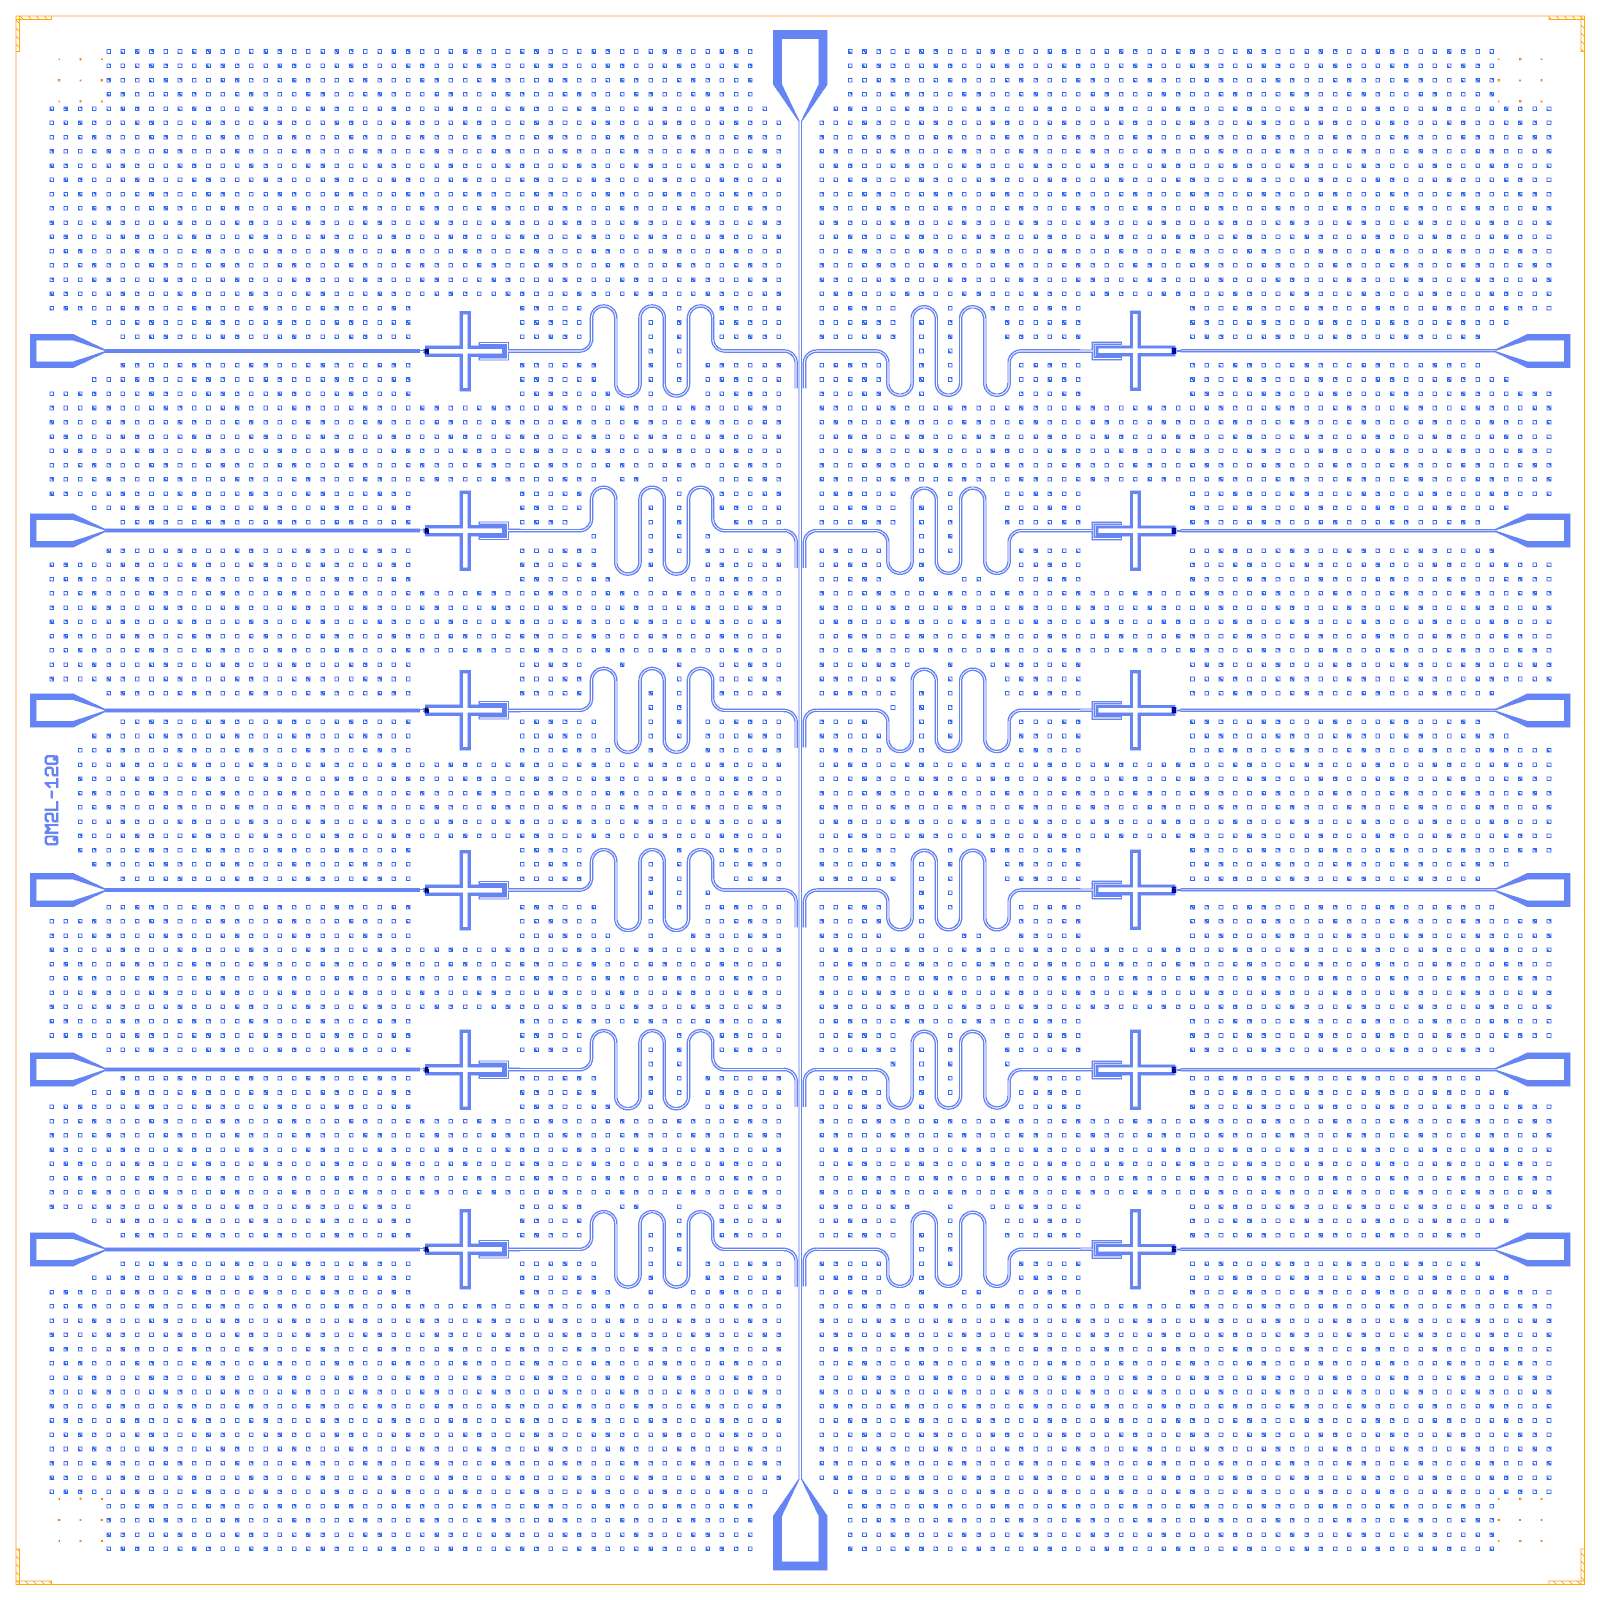

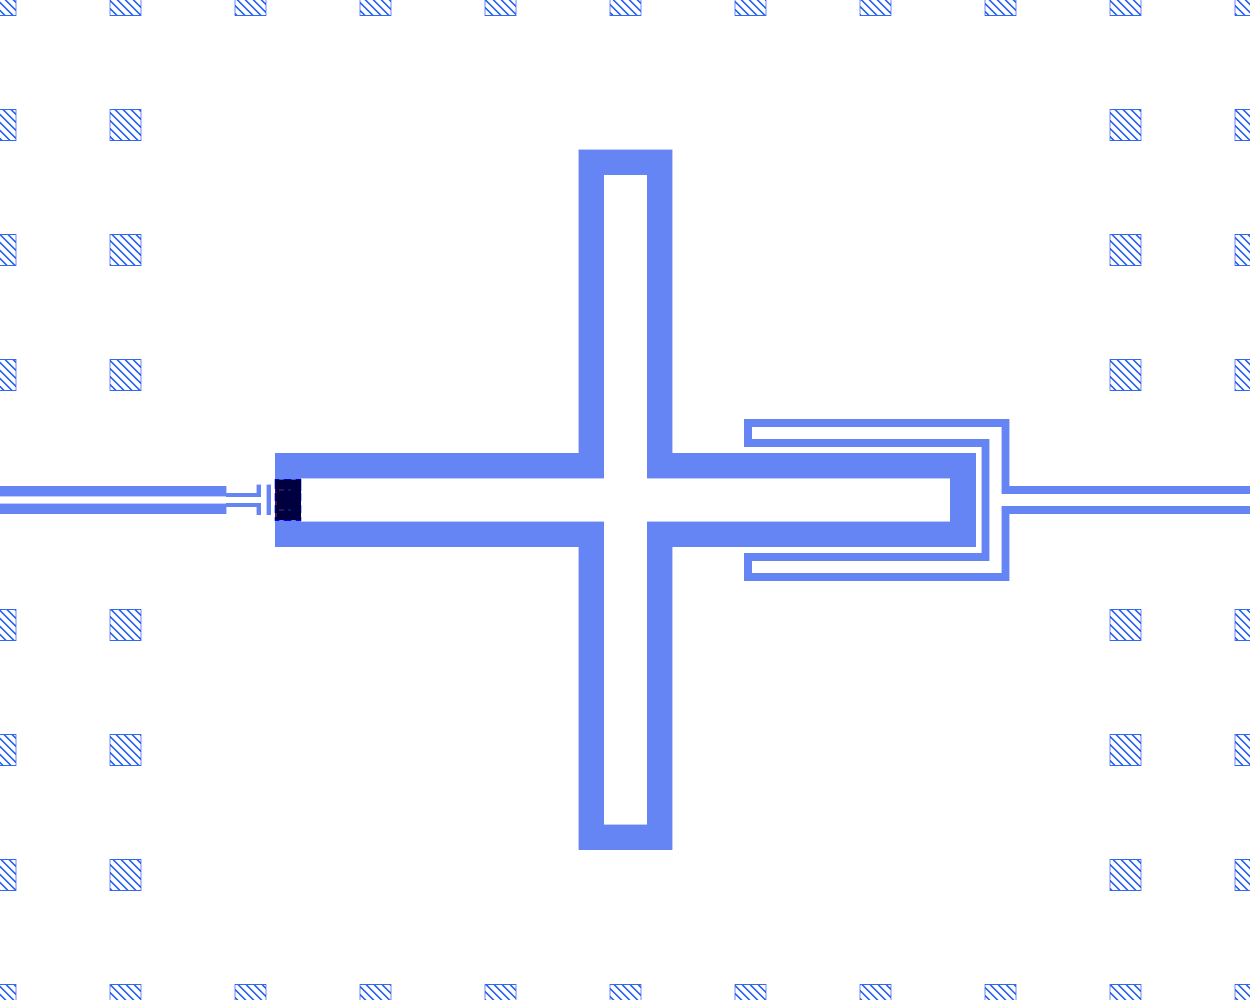

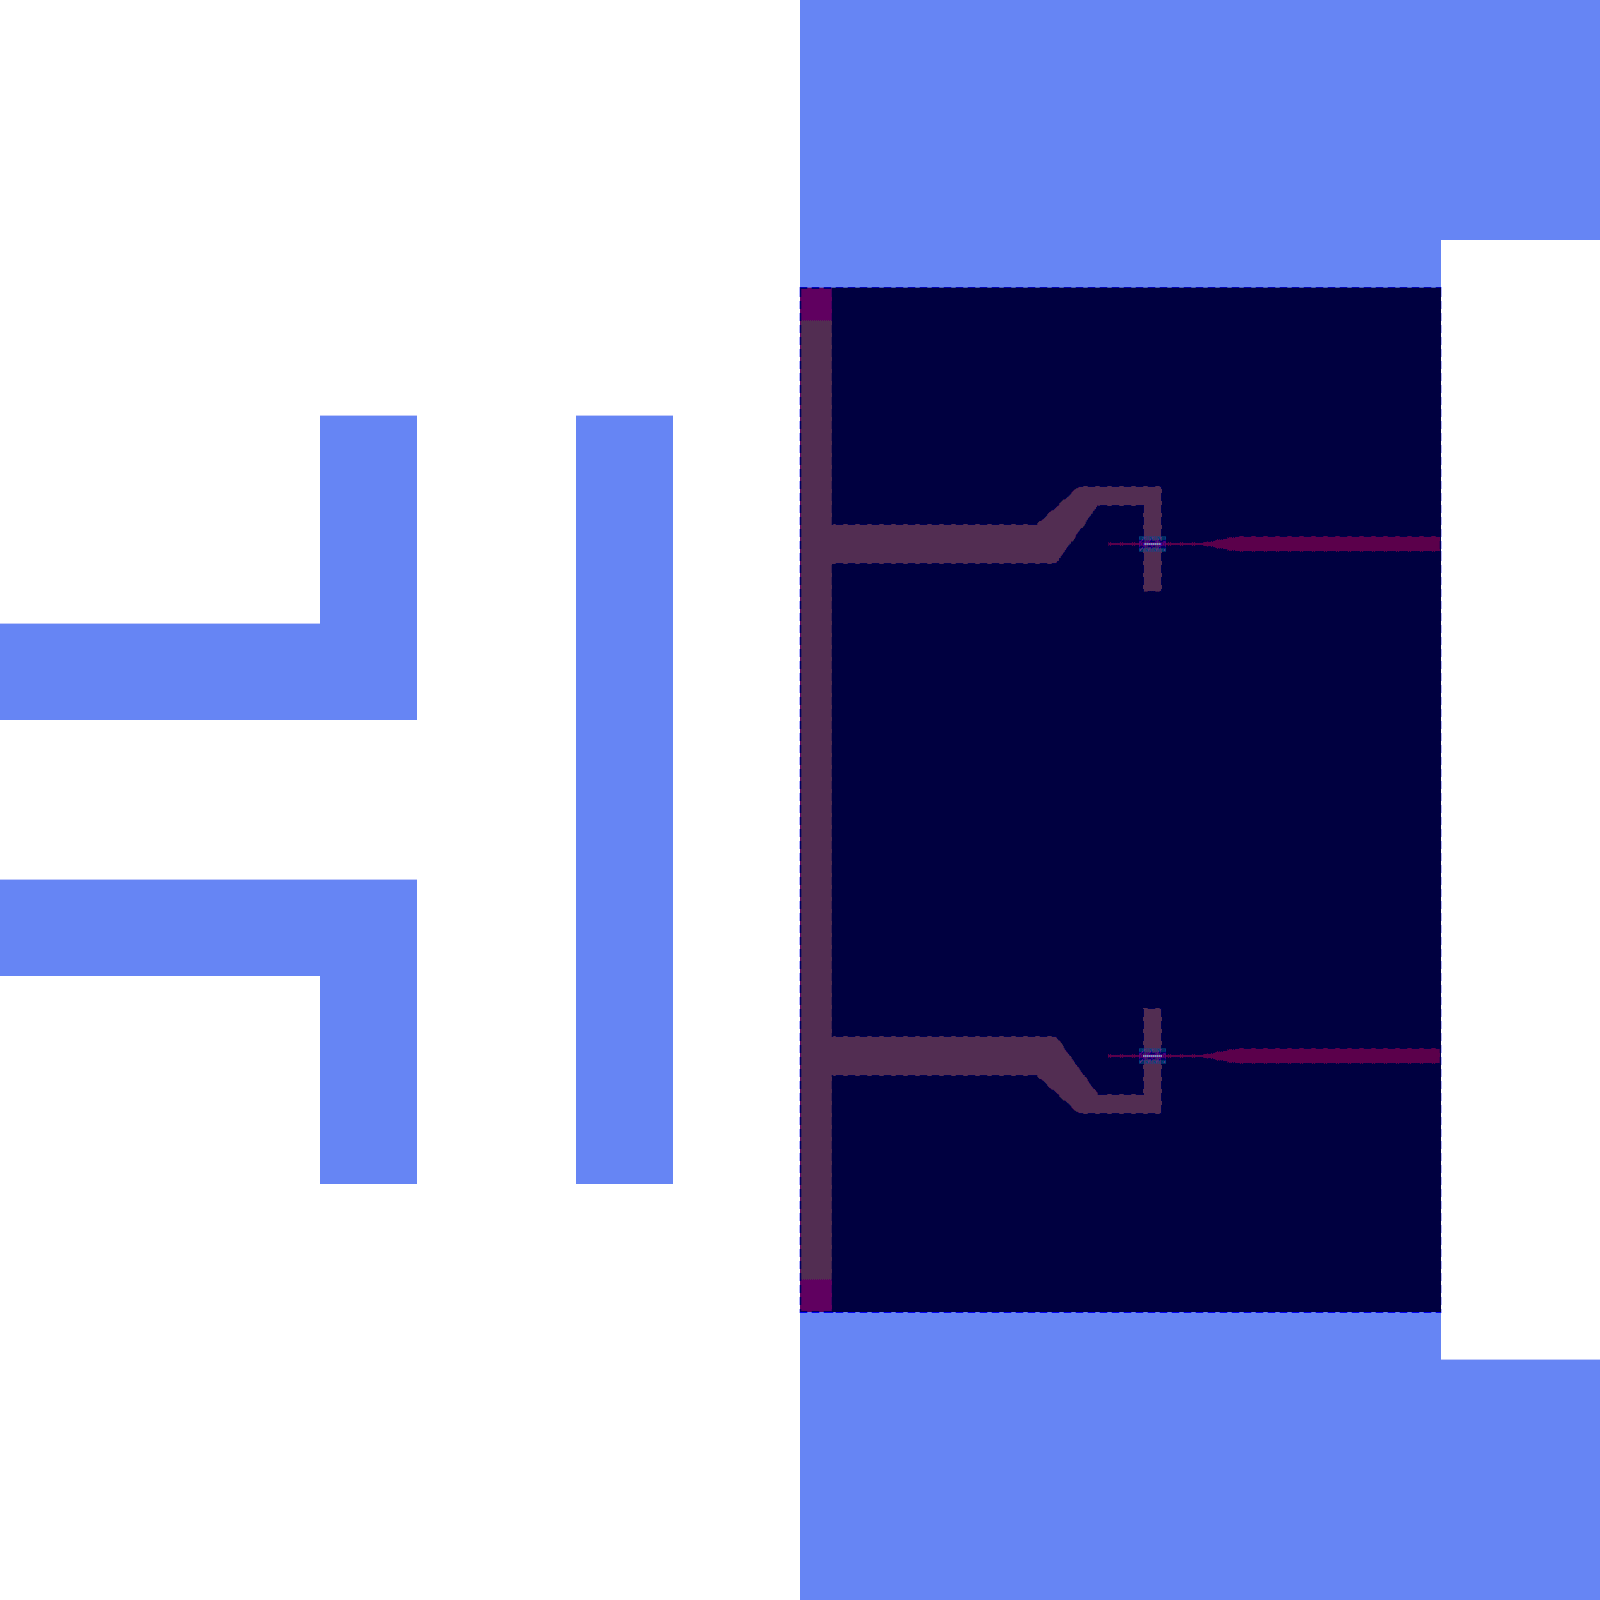

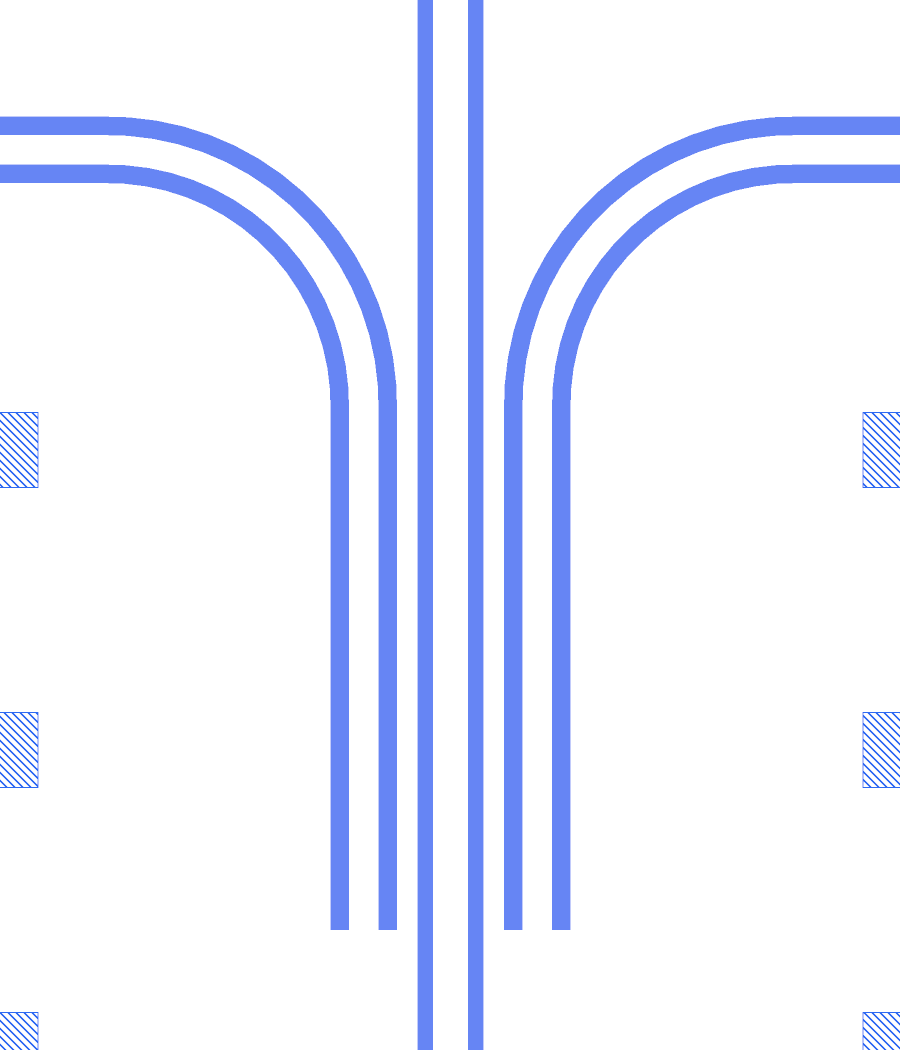

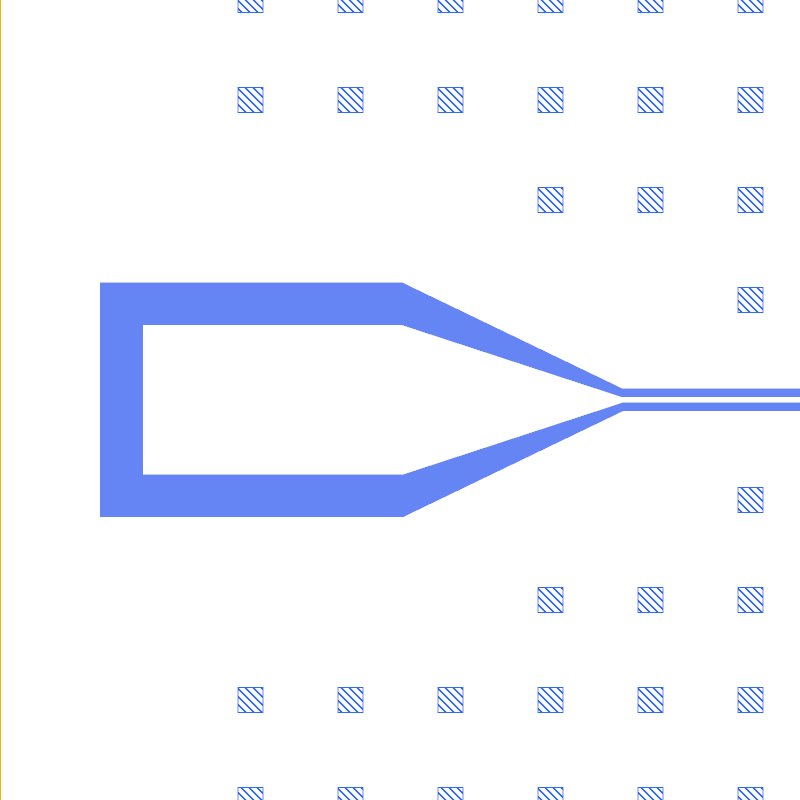

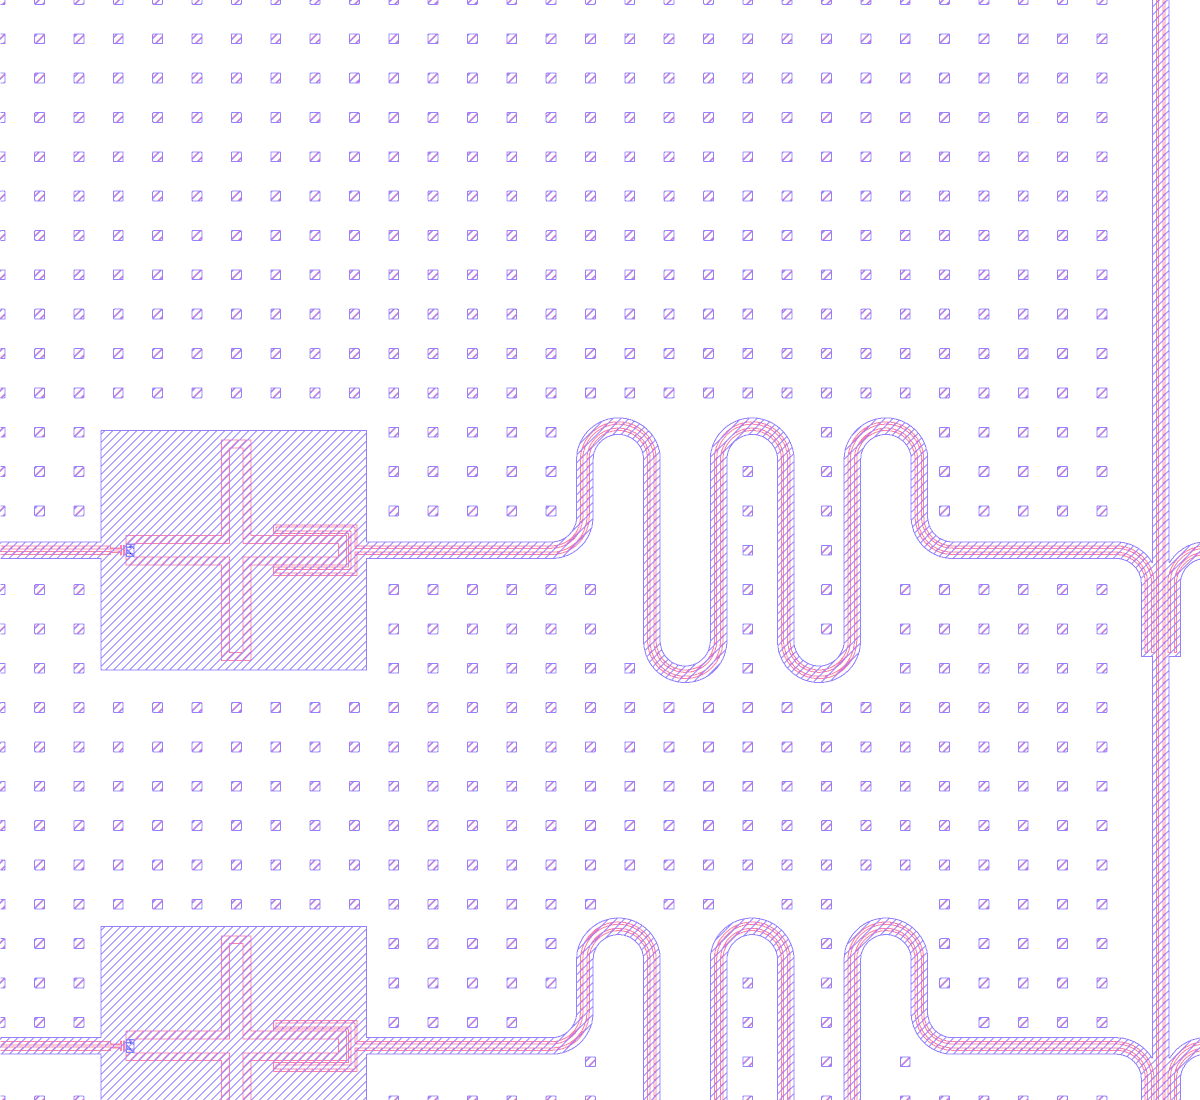

In [17]:
snap(d, OUT / "qm2litho_12q_flux_processor.png", size=(1600, 1600))
qx, qy = X0 - 2350, Y0 + 3150
snap(d, OUT / "qm2litho_12q_flux_processor_q01l.png", box=(qx - 500, qy - 400, qx + 500, qy + 400), size=(1250, 1000), width=450)
snap(d, OUT / "qm2litho_12q_flux_processor_jj.png", box=(qx - 305, qy - 25, qx - 255, qy + 25), width=300)
snap(d, OUT / "qm2litho_12q_flux_processor_couplers.png", box=(X0 - 150, qy - 300, X0 + 150, qy + 50), size=(900, 1050), width=340)
snap(d, OUT / "qm2litho_12q_flux_processor_fluxpad.png", box=(0, qy - 400, 800, qy + 400), size=(800, 800), width=300)
snap_file(Path("build") / "qm2litho_12q_flux_processor_fab.oas", OUT / "qm2litho_12q_flux_processor_cheese.png",
          box=(qx - 600, qy - 500, X0 + 100, qy + 500), size=(1200, 1100), width=420);

## 15 · Summary

- **Matches the source:** the qubit cell and its options, the positions, the feedline CPW, the readout plan and
  lengths, the hanger couplers (the spec's reading of the 18 µm gap), the flux lines, the source's L_J, and Metal's GDS
  cheese (25 µm / 100 µm, 25 µm buffer), drawn by the build and kept in the mask (9210 holes).
- **Changed by the PDK:** the PDK frame on the 11 × 11 mm die, sapphire, drawn trilayer SQUIDs (15.31 nH on the finger
  grid), the launch and flux pads 100 µm from the die edge (the feedline and the flux lines are longer), content centred
  (no shift needed).
- **Open PDK design warnings:** `pdk_rn` on all twelve SQUIDs (device R_n 102 kΩ at the source's 15.9 nH; flagged, not
  retuned). The qubits sit at 3.26 GHz, below the PDK band (no target, so no `pdk_fq`); the readouts 5–6 % below the
  source's plan.
- **Open:** the FEM jobs are exported, not solved (`RUN_FEM = False`).